In [1]:
%pip install sqlalchemy "psycopg[binary]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 10.1 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [psycopg]m1/2 [psycopg]
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
from getpass import getpass
from sqlalchemy import URL, create_engine, text

connection_url = URL.create(
    drivername="postgresql+psycopg",
    username=input("Username из pgAdmin: "),
    password=getpass("Пароль PostgreSQL: "),
    host="localhost",
    port=5432,
    database="olist_analytics",
)

engine = create_engine(connection_url)

with engine.connect() as connection:
    database = connection.execute(
        text("SELECT current_database()")
    ).scalar()

print("Подключено к базе:", database)

Подключено к базе: olist_analytics


In [3]:
with engine.connect() as connection:
    orders = pd.read_sql_query(
        text("SELECT * FROM mart.orders"),
        connection,
    )

orders.head()

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_customer_date,order_estimated_delivery_date,is_late,delivery_days,customer_id,customer_unique_id,customer_state,item_count,seller_count,single_seller_id,seller_state,is_interstate,items_total,freight_total,payment_total,review_score
0,00042b26cf59d7ce69dfabb4e55b4fd9,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-03-01 16:42:31,2017-03-17,False,25.114352,58dbd0b2d70206bf40e62cd34e84d795,64b576fb70d441e8f1b2d7d446e483c5,SP,1.0,1.0,df560393f3a51e74553ab94004ba5c87,PR,True,199.9,18.14,218.04,5.0
1,00048cc3ae777c65dbb7d2a0634bc1ea,delivered,2017-05-15 21:42:34,2017-05-17 03:55:27,2017-05-22 13:44:35,2017-06-06,False,6.668067,816cbea969fe5b689b39cfc97a506742,85c835d128beae5b4ce8602c491bf385,MG,1.0,1.0,6426d21aca402a131fc0a5d0960a3c90,SP,True,21.9,12.69,34.59,4.0
2,00054e8431b9d7675808bcb819fb4a32,delivered,2017-12-10 11:53:48,2017-12-10 12:10:31,2017-12-18 22:03:38,2018-01-04,False,8.423495,32e2e6ab09e778d99bf2e0ecd4898718,635d9ac1680f03288e72ada3a1035803,SP,1.0,1.0,7040e82f899a04d1b434b795a43b4617,SP,False,19.9,11.85,31.75,4.0
3,000c3e6612759851cc3cbb4b83257986,delivered,2017-08-12 10:08:57,2017-08-15 03:35:32,2017-08-19 15:22:17,2017-09-01,False,7.217593,3773bcf1a6fbd29233ea1c1b573c4f22,f5f088001070650f9e9a8cd773621f35,SP,1.0,1.0,218d46b86c1881d022bce9c68a7d4b15,SP,False,99.0,13.71,112.71,5.0
4,000e63d38ae8c00bbcb5a30573b99628,delivered,2018-03-23 19:48:26,2018-03-23 20:07:49,2018-03-27 14:51:47,2018-04-05,False,3.793993,98884e672c5ba85f4394f2044e1a3eab,860fc00d3154ce2346c43ebe47b9b6ce,SP,1.0,1.0,1c129092bf23f28a5930387c980c0dfc,SP,False,47.9,8.88,56.78,3.0


In [4]:
print("Строк:", len(orders))
print("Уникальных заказов:", orders["order_id"].nunique())
print("Заказов с известным is_late:", orders["is_late"].notna().sum())

Строк: 99441
Уникальных заказов: 99441
Заказов с известным is_late: 96470


# Проверка доля опозданий различается между штатами покупателей.

In [13]:
delivery_orders = orders[orders["is_late"].notna()].copy()

In [12]:
delivery_orders["customer_state"].isna().sum()

np.int64(0)

In [17]:
state_stats = (delivery_orders.groupby("customer_state").agg(
    orders_count = ("order_id", "size"),
    late_orders = ("is_late", "sum"),
    late_rate = ("is_late", "mean"),
    )
)
state_stats["late_rate"] = (state_stats["late_rate"] * 100).round(2)

state_stats.sort_values("late_rate", ascending=False)

,orders_count,late_orders,late_rate
customer_state,,,
AL,397,85,21.41
MA,717,125,17.43
SE,335,51,15.22
PI,476,66,13.87
CE,1279,176,13.76
RR,41,5,12.2
BA,3256,396,12.16
RJ,12350,1495,12.11
PA,946,106,11.21


In [18]:
overall_late_rate = delivery_orders["is_late"].mean() * 100
print("Всего опозданий %:", round(overall_late_rate, 2))

Всего опозданий %: 6.77


In [19]:
display(state_stats.sort_values("late_rate", ascending=False).head(5))

display(state_stats.sort_values("late_orders", ascending=False).head(5))

,orders_count,late_orders,late_rate
customer_state,,,
AL,397,85,21.41
MA,717,125,17.43
SE,335,51,15.22
PI,476,66,13.87
CE,1279,176,13.76


,orders_count,late_orders,late_rate
customer_state,,,
SP,40494,1820,4.49
RJ,12350,1495,12.11
MG,11354,519,4.57
BA,3256,396,12.16
RS,5344,325,6.08


# Промежуточные выводы
Штаты с максимальной долей опозданий отличаются от лидеров по абсолютному числу просроченных заказов.

Для детального анализа выбираем 4 штата

RJ - большой объем заказов и большая доля опозданий 

BA - большой объем заказов и большая доля опозданий 

AL - максимальная доля опозданий

SP - максимальное число опозданий

In [32]:
delivery_orders["purchase_month"] = delivery_orders["order_purchase_timestamp"].dt.to_period("M")
sel = delivery_orders[delivery_orders["customer_state"].isin(["RJ", "BA", "AL", "SP"])].copy()
sel["is_late"] = sel["is_late"].astype("int64")
an_states = sel.groupby(["purchase_month", "customer_state"]).agg(
    orders_count=("order_id", "size"),
    late_orders=("is_late", "sum"),
    late_rate=("is_late", "mean"),
)
an_states["late_rate"] = (an_states["late_rate"] * 100).round(2)
an_states


orders_count  late_orders  late_rate
purchase_month customer_state                                      
2016-09        SP                         1            1     100.00
2016-10        AL                         1            0       0.00
               BA                         3            0       0.00
               RJ                        40            0       0.00
               SP                        94            2       2.13
...                                     ...          ...        ...
2018-07        SP                      2712          100       3.69
2018-08        AL                        16            0       0.00
               BA                       159            1       0.63
               RJ                       723           42       5.81
               SP                      3164          285       9.01

[85 rows x 3 columns]

In [33]:
monthly_rates = an_states["late_rate"].unstack("customer_state")
monthly_rates

customer_state,AL,BA,RJ,SP
purchase_month,,,,
2016-09,NaN,NaN,NaN,100.00
2016-10,0.00,0.00,0.00,2.13
2017-01,0.00,4.17,3.30,2.83
2017-02,8.33,8.62,3.48,3.00
2017-03,20.00,8.05,4.32,2.28
2017-04,38.10,14.29,6.46,6.99
2017-05,7.69,3.36,2.79,4.26
2017-06,30.00,7.77,3.26,3.27
2017-07,46.67,4.86,3.11,1.81


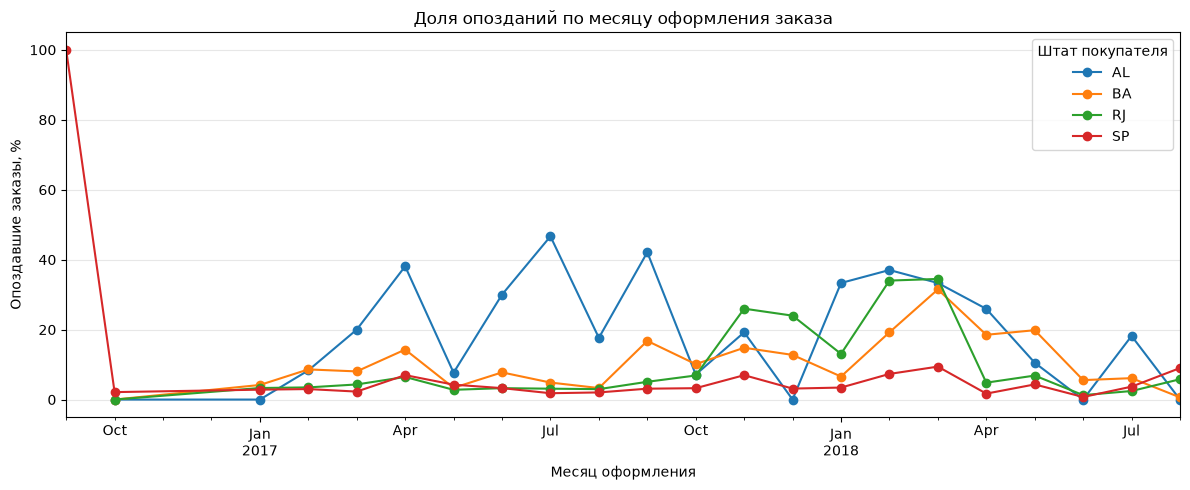

In [34]:
import matplotlib.pyplot as plt

ax = monthly_rates.plot(figsize=(12, 5), marker="o")

ax.set_title("Доля опозданий по месяцу оформления заказа")
ax.set_xlabel("Месяц оформления")
ax.set_ylabel("Опоздавшие заказы, %")
ax.legend(title="Штат покупателя")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [37]:
an_states.loc["2017-10":"2018-03"]

orders_count  late_orders  late_rate
purchase_month customer_state                                      
2017-10        AL                        28            2       7.14
               BA                       158           16      10.13
               RJ                       654           45       6.88
               SP                      1723           56       3.25
2017-11        AL                        26            5      19.23
               BA                       243           36      14.81
               RJ                      1012          263      25.99
               SP                      2898          202       6.97
2017-12        AL                        12            0       0.00
               BA                       188           24      12.77
               RJ                       746          179      23.99
               SP                      2295           72       3.14
2018-01        AL                        36           12      33.33
               BA                       228           15       6.58
               RJ                       850          111      13.06
               SP                      2975          102       3.43
2018-02        AL                        27           10      37.04
               BA                       208           40      19.23
               RJ                       879          299      34.02
               SP                      2632          193       7.33
2018-03        AL                        27            9      33.33
               BA                       235           74      31.49
               RJ                       864          298      34.49
               SP                      2971          280       9.42

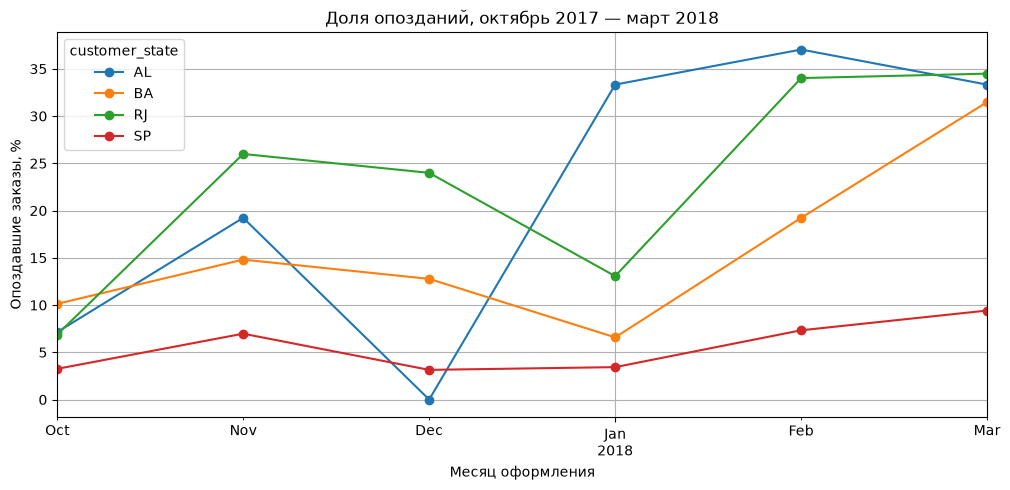

In [38]:
monthly_rates.loc["2017-10":"2018-03"].plot(
    figsize=(12, 5),
    marker="o",
    ylabel="Опоздавшие заказы, %",
    xlabel="Месяц оформления",
    title="Доля опозданий, октябрь 2017 — март 2018",
    grid=True,
)
plt.show()

# Выводы

# Проверка 2-й гипотезы: доставки между штатами опаздывают чаще, чем внутри одного штата.

In [43]:
route_check = delivery_orders[delivery_orders["is_interstate"].notna()].copy()
route_check

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_customer_date,order_estimated_delivery_date,is_late,delivery_days,customer_id,customer_unique_id,...,item_count,seller_count,single_seller_id,seller_state,is_interstate,items_total,freight_total,payment_total,review_score,purchase_month
0,00042b26cf59d7ce69dfabb4e55b4fd9,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-03-01 16:42:31,2017-03-17,False,25.114352,58dbd0b2d70206bf40e62cd34e84d795,64b576fb70d441e8f1b2d7d446e483c5,...,1.0,1.0,df560393f3a51e74553ab94004ba5c87,PR,True,199.90,18.14,218.04,5.0,2017-02
1,00048cc3ae777c65dbb7d2a0634bc1ea,delivered,2017-05-15 21:42:34,2017-05-17 03:55:27,2017-05-22 13:44:35,2017-06-06,False,6.668067,816cbea969fe5b689b39cfc97a506742,85c835d128beae5b4ce8602c491bf385,...,1.0,1.0,6426d21aca402a131fc0a5d0960a3c90,SP,True,21.90,12.69,34.59,4.0,2017-05
2,00054e8431b9d7675808bcb819fb4a32,delivered,2017-12-10 11:53:48,2017-12-10 12:10:31,2017-12-18 22:03:38,2018-01-04,False,8.423495,32e2e6ab09e778d99bf2e0ecd4898718,635d9ac1680f03288e72ada3a1035803,...,1.0,1.0,7040e82f899a04d1b434b795a43b4617,SP,False,19.90,11.85,31.75,4.0,2017-12
3,000c3e6612759851cc3cbb4b83257986,delivered,2017-08-12 10:08:57,2017-08-15 03:35:32,2017-08-19 15:22:17,2017-09-01,False,7.217593,3773bcf1a6fbd29233ea1c1b573c4f22,f5f088001070650f9e9a8cd773621f35,...,1.0,1.0,218d46b86c1881d022bce9c68a7d4b15,SP,False,99.00,13.71,112.71,5.0,2017-08
4,000e63d38ae8c00bbcb5a30573b99628,delivered,2018-03-23 19:48:26,2018-03-23 20:07:49,2018-03-27 14:51:47,2018-04-05,False,3.793993,98884e672c5ba85f4394f2044e1a3eab,860fc00d3154ce2346c43ebe47b9b6ce,...,1.0,1.0,1c129092bf23f28a5930387c980c0dfc,SP,False,47.90,8.88,56.78,3.0,2018-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99436,fffb2ef8874127f75b52b643880fd7e0,delivered,2018-03-30 15:36:49,2018-04-03 05:08:33,2018-04-16 16:56:38,2018-04-27,False,17.055428,ca8374c00203cec663bc1eabf0aaede4,6b42acb204802253acec6607ff3a9e0b,...,1.0,1.0,609e1a9a6c2539919b8205cf7c4e6ff0,SC,True,17.90,22.06,39.96,5.0,2018-03
99437,fffb9224b6fc7c43ebb0904318b10b5f,delivered,2017-10-27 16:51:00,2017-10-28 02:55:58,2017-11-17 19:41:42,2017-11-27,False,21.118542,4d3abb73ceb86353aeadbe698aa9d5cb,f736308cd9952b33b90b9fe94da9c8f5,...,4.0,1.0,b1fc4f64df5a0e8b6913ab38803c57a9,RJ,True,220.00,136.76,356.76,4.0,2017-10
99438,fffc94f6ce00a00581880bf54a75a037,delivered,2018-04-23 13:57:06,2018-04-25 04:11:01,2018-05-10 22:56:40,2018-05-18,False,17.374699,b51593916b4b8e0d6f66f2ae24f2673d,0c9aeda10a71f369396d0c04dce13a64,...,1.0,1.0,b8bc237ba3788b23da09c0f1f3a3288c,SC,True,299.99,43.41,343.40,5.0,2018-04
99439,fffcd46ef2263f404302a634eb57f7eb,delivered,2018-07-14 10:26:46,2018-07-17 04:31:48,2018-07-23 20:31:55,2018-08-01,False,9.420243,84c5d4fbaf120aae381fad077416eaa0,0da9fe112eae0c74d3ba1fe16de0988b,...,1.0,1.0,f3c38ab652836d21de61fb8314b69182,SP,True,350.00,36.53,386.53,5.0,2018-07


In [44]:
res = route_check.groupby(["is_interstate"]).agg(
    orders_count=("order_id", "size"),
    late_orders=("is_late", "sum"),
    late_rate=("is_late", "mean"),
)

res["late_rate"] = (res["late_rate"] * 100).round(2)
res


,orders_count,late_orders,late_rate
is_interstate,,,
False,34234,1560,4.56
True,60961,4961,8.14


# Выводы 
Доля опозданий при заказе между штатами в 1,8 раз выше чем в заказах внутри штата

# Проверка 3-й гипотезы: Опоздавшие заказы чаще получают оценки 1-2

In [56]:
has_rev = delivery_orders.groupby("is_late").agg(
    total_orders = ("order_id", "size"),
    rated = ("review_score", "count")
)
has_rev

,total_orders,rated
is_late,,
False,89936,89443
True,6534,6381


In [57]:
delivery_orders = orders[orders["is_late"].notna()].copy()
print(len(delivery_orders))

96470


In [60]:
has_rev["coverage"] = (
    has_rev["rated"] / has_rev["total_orders"] * 100
).round(2)

has_rev

,total_orders,rated,coverage_pct,coverage
is_late,,,,
False,89936,89443,99.45,99.45
True,6534,6381,97.66,97.66


In [61]:
rated_orders = delivery_orders[delivery_orders["review_score"].notna()].copy()

rated_orders["low_rating"] = rated_orders["review_score"].isin([1, 2])

In [64]:
review_stats = rated_orders.groupby("is_late").agg(
    rated_orders = ("order_id", "size"),
    low_score_orders = ("low_rating", "sum"),
    low_score_rate = ("low_rating", "mean")
)

review_stats["low_score_rate"] = (review_stats["low_score_rate"] * 100).round(2)

review_stats

,rated_orders,low_score_orders,low_score_rate
is_late,,,
False,89443,8289,9.27
True,6381,3983,62.42


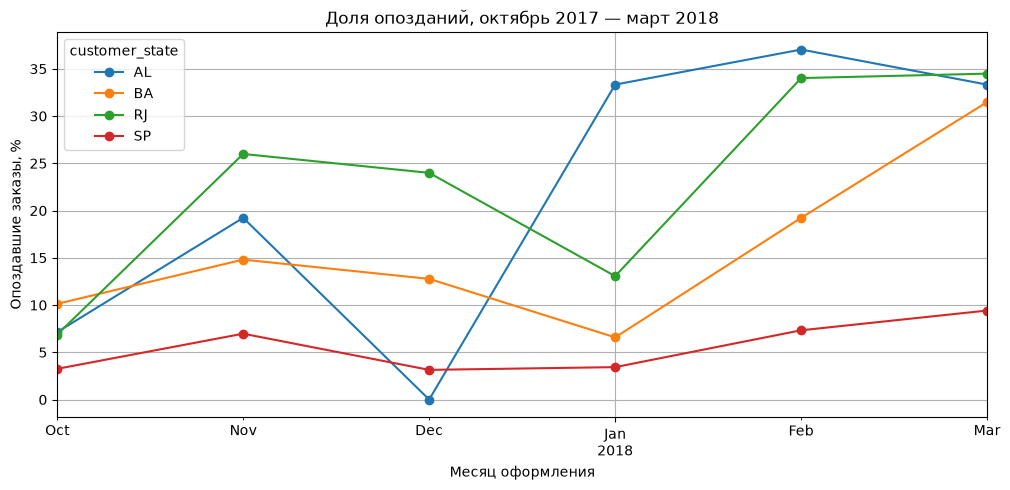

In [67]:
monthly_rates.loc["2017-10":"2018-03"].plot(
    figsize=(12, 5),
    marker="o",
    ylabel="Опоздавшие заказы, %",
    xlabel="Месяц оформления",
    title="Доля опозданий, октябрь 2017 — март 2018",
    grid=True,
)
plt.show()

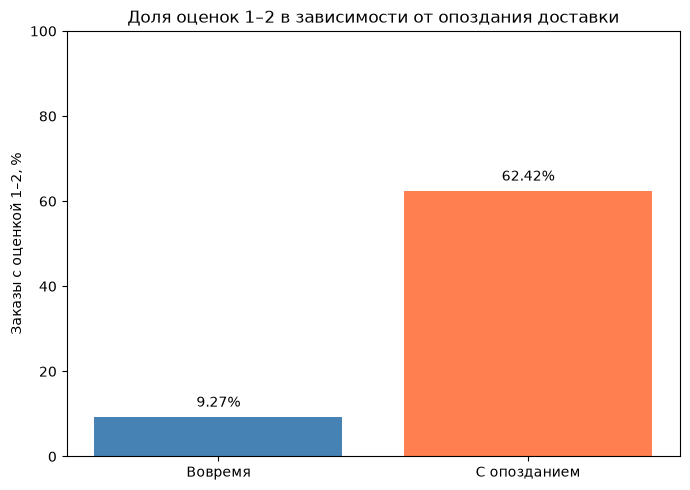

In [68]:
import matplotlib.pyplot as plt

rates = review_stats["low_score_rate"].reindex([False, True])

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["Вовремя", "С опозданием"],
    rates,
    color=["steelblue", "coral"],
)

ax.bar_label(bars, fmt="%.2f%%", padding=5)
ax.set_title("Доля оценок 1–2 в зависимости от опоздания доставки")
ax.set_ylabel("Заказы с оценкой 1–2, %")
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

# Выводы
Оценки 1-2 звезды:
9.27% у заказов, пришедщих вовремя, 62.42% у заказов с опопзданием. Разница 53.15 п.п